In [1]:
import zipfile
import os

zip_path = '/content/archive_3.zip'
extract_path = '/content/extracted_data'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted files:")
os.listdir(extract_path)

Extracted files:


['starbucks.csv']

In [2]:
import pandas as pd
import glob

# Find CSV files in the extracted directory
csv_files = glob.glob(f'{extract_path}/**/*.csv', recursive=True)
if csv_files:
    df = pd.read_csv(csv_files[0])
    print(f"Loaded file: {csv_files[0]}")
    display(df.info())
    display(df.head())
else:
    print("No CSV files found in the archive.")

Loaded file: /content/extracted_data/starbucks.csv
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Beverage_category          242 non-null    object 
 1   Beverage                   242 non-null    object 
 2   Beverage_prep              242 non-null    object 
 3   Calories                   242 non-null    int64  
 4    Total Fat (g)             242 non-null    object 
 5   Trans Fat (g)              242 non-null    float64
 6   Saturated Fat (g)          242 non-null    float64
 7    Sodium (mg)               242 non-null    int64  
 8    Total Carbohydrates (g)   242 non-null    int64  
 9   Cholesterol (mg)           242 non-null    int64  
 10   Dietary Fibre (g)         242 non-null    int64  
 11   Sugars (g)                242 non-null    int64  
 12   Protein (g)               242 non-null    float64
 13 

None

,Beverage_category,Beverage,Beverage_prep,Calories,Total Fat (g),Trans Fat (g),Saturated Fat (g),Sodium (mg),Total Carbohydrates (g),Cholesterol (mg),Dietary Fibre (g),Sugars (g),Protein (g),Vitamin A (% DV),Vitamin C (% DV),Calcium (% DV),Iron (% DV),Caffeine (mg)
0,Coffee,Brewed Coffee,Short,3,0.1,0.0,0.0,0,5,0,0,0,0.3,0%,0%,0%,0%,175
1,Coffee,Brewed Coffee,Tall,4,0.1,0.0,0.0,0,10,0,0,0,0.5,0%,0%,0%,0%,260
2,Coffee,Brewed Coffee,Grande,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,0%,0%,330
3,Coffee,Brewed Coffee,Venti,5,0.1,0.0,0.0,0,10,0,0,0,1.0,0%,0%,2%,0%,410
4,Classic Espresso Drinks,Caffè Latte,Short Nonfat Milk,70,0.1,0.1,0.0,5,75,10,0,9,6.0,10%,0%,20%,0%,75


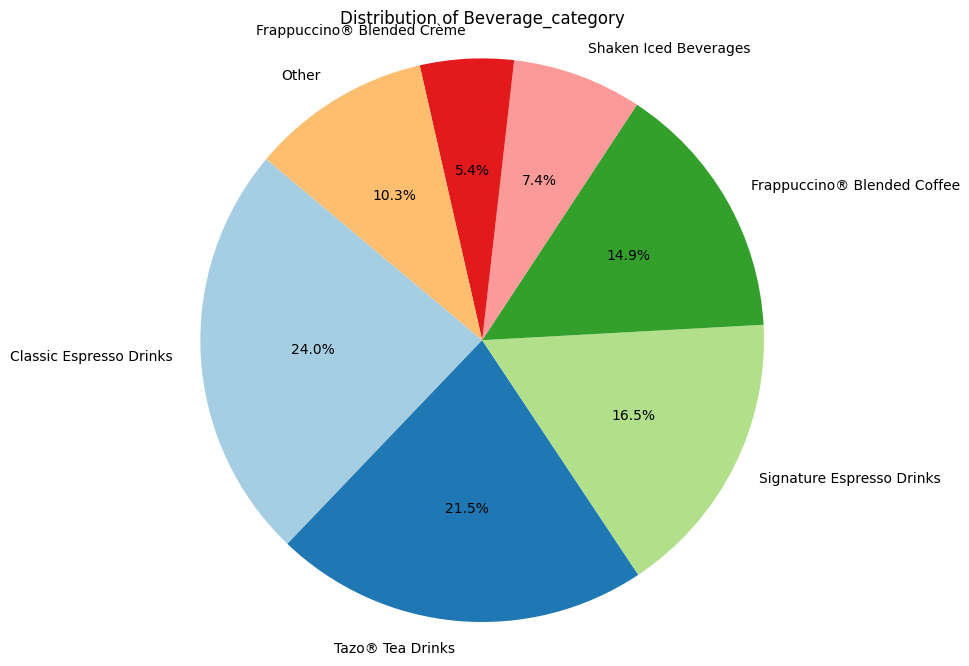

In [3]:
import matplotlib.pyplot as plt

# Identify a categorical column to plot as a pie chart
# We will select the first object/categorical column with a reasonable number of unique values
cat_cols = [col for col in df.columns if df[col].dtype == 'object' or df[col].nunique() < 10]

if cat_cols:
    target_col = cat_cols[0]
    value_counts = df[target_col].value_counts()

    # If there are too many categories, group the smaller ones into 'Other'
    if len(value_counts) > 7:
        top_categories = value_counts.head(6)
        other_sum = value_counts.iloc[6:].sum()
        value_counts = pd.concat([top_categories, pd.Series({'Other': other_sum})])

    plt.figure(figsize=(8, 8))
    plt.pie(value_counts, labels=value_counts.index, autopct='%1.1f%%', startangle=140, colors=plt.cm.Paired.colors)
    plt.title(f'Distribution of {target_col}')
    plt.axis('equal')
    plt.show()
else:
    print("No suitable categorical column found for a pie chart.")

### Preparing Data and Training a Decision Tree Classifier
We will preprocess the nutritional features, convert object columns with numeric data to numeric types, handle missing values, split the data 80/20, and fit a Decision Tree Classifier.

In [4]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score
import re

# Make a copy of the dataframe to avoid settings copy warnings
ml_df = df.copy()

# Clean up column names by stripping spaces
ml_df.columns = ml_df.columns.str.strip()

# Columns with numeric values that need cleaning
columns_to_numeric = [
    'Total Fat (g)', 'Vitamin A (% DV)', 'Vitamin C (% DV)',
    'Calcium (% DV)', 'Iron (% DV)', 'Caffeine (mg)'
]

def clean_and_convert(val):
    if pd.isna(val):
        return np.nan
    val_str = str(val).strip().replace('%', '')
    # Extract first numeric/decimal value found or return NaN
    match = re.search(r'[-+]?\d*\.\d+|\d+', val_str)
    if match:
        return float(match.group())
    return np.nan

for col in columns_to_numeric:
    if col in ml_df.columns:
        ml_df[col] = ml_df[col].apply(clean_and_convert)

# Define feature columns (all nutritional metrics)
features = [
    'Calories', 'Total Fat (g)', 'Trans Fat (g)', 'Saturated Fat (g)',
    'Sodium (mg)', 'Total Carbohydrates (g)', 'Cholesterol (mg)',
    'Dietary Fibre (g)', 'Sugars (g)', 'Protein (g)',
    'Vitamin A (% DV)', 'Vitamin C (% DV)', 'Calcium (% DV)',
    'Iron (% DV)', 'Caffeine (mg)'
]

# Drop rows where target 'Beverage_category' is missing
ml_df = ml_df.dropna(subset=['Beverage_category'])

# Fill missing values in features with the median
for col in features:
    ml_df[col] = ml_df[col].fillna(ml_df[col].median())

X = ml_df[features]
y = ml_df['Beverage_category']

# Split the dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")

Training set size: 193 samples
Testing set size: 49 samples


In [5]:
# Initialize and train the Decision Tree Classifier
clf = DecisionTreeClassifier(max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# Predict on the test set
y_pred = clf.predict(X_test)

# Calculate and print metrics
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy:.2%}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 69.39%

Classification Report:
                                   precision    recall  f1-score   support

          Classic Espresso Drinks       0.67      0.33      0.44        12
                           Coffee       1.00      1.00      1.00         1
      Frappuccino® Blended Coffee       0.88      1.00      0.93         7
       Frappuccino® Blended Crème       1.00      1.00      1.00         3
Frappuccino® Light Blended Coffee       1.00      0.50      0.67         2
            Shaken Iced Beverages       1.00      0.75      0.86         4
        Signature Espresso Drinks       0.33      0.50      0.40         8
                        Smoothies       1.00      1.00      1.00         2
                 Tazo® Tea Drinks       0.69      0.90      0.78        10

                         accuracy                           0.69        49
                        macro avg       0.84      0.78      0.79        49
                     weighted avg       0.73      0

### Visualizing Model Feature Importances
Let's visualize which nutritional features have the most influence on our Decision Tree's classifications.

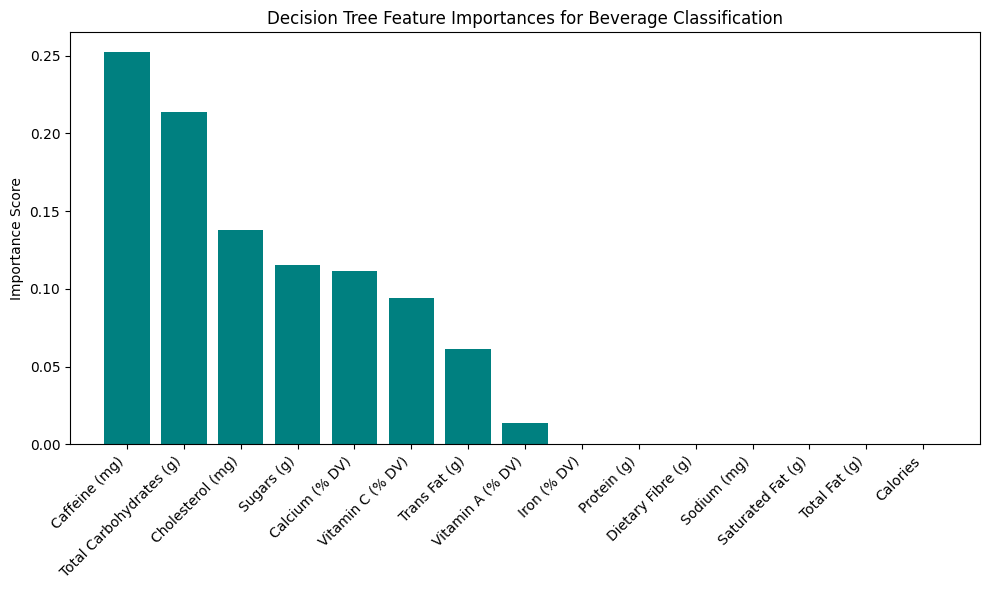

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Get feature importances from the trained model
importances = clf.feature_importances_
indices = np.argsort(importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(10, 6))
plt.title("Decision Tree Feature Importances for Beverage Classification")
plt.bar(range(X.shape[1]), importances[indices], color="teal", align="center")
plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=45, ha="right")
plt.xlim([-1, X.shape[1]])
plt.ylabel("Importance Score")
plt.tight_layout()
plt.show()

### Model Predictions vs Actual Labels (Sample of 10 Drinks)
Let's pick 10 drinks from our testing dataset and compare the actual beverage category with the one predicted by our Decision Tree model.

In [7]:
# Select the first 10 indices from the test set
sample_indices = X_test.index[:10]

# Retrieve corresponding beverage names and preparation styles from df
sample_names = df.loc[sample_indices, 'Beverage']
sample_preps = df.loc[sample_indices, 'Beverage_prep']

# Get features and actual target values for these 10 drinks
X_sample = X_test.head(10)
y_sample_actual = y_test.head(10)

# Generate predictions for this sample
y_sample_pred = clf.predict(X_sample)

# Combine everything into a display DataFrame
comparison_df = pd.DataFrame({
    'Beverage Name': sample_names,
    'Preparation': sample_preps,
    'Actual Category': y_sample_actual,
    'Predicted Category': y_sample_pred
}).reset_index(drop=True)

display(comparison_df)

,Beverage Name,Preparation,Actual Category,Predicted Category
0,Mocha (Without Whipped Cream),Whole Milk,Frappuccino® Blended Coffee,Frappuccino® Blended Coffee
1,Hot Chocolate (Without Whipped Cream),Soymilk,Signature Espresso Drinks,Tazo® Tea Drinks
2,Caffè Americano,Grande,Classic Espresso Drinks,Classic Espresso Drinks
3,Vanilla Latte (Or Other Flavoured Latte),2% Milk,Classic Espresso Drinks,Signature Espresso Drinks
4,Tazo® Chai Tea Latte,2% Milk,Tazo® Tea Drinks,Tazo® Tea Drinks
5,Caffè Latte,2% Milk,Classic Espresso Drinks,Signature Espresso Drinks
6,Cappuccino,Soymilk,Classic Espresso Drinks,Classic Espresso Drinks
7,Iced Brewed Coffee (With Classic Syrup),Grande,Shaken Iced Beverages,Shaken Iced Beverages
8,Brewed Coffee,Grande,Coffee,Coffee
9,Caramel Macchiato,Short Nonfat Milk,Signature Espresso Drinks,Tazo® Tea Drinks


### Saving the Trained Model
We will serialize and save our Decision Tree Classifier model using the `pickle` module.

In [8]:
import pickle

model_path = '/content/starbucks_decision_tree_model.pkl'

with open(model_path, 'wb') as file:
    pickle.dump(clf, file)

print(f"Model successfully saved to: {model_path}")

Model successfully saved to: /content/starbucks_decision_tree_model.pkl
